In [1]:
import ast
from collections import Counter
import json
import re
import time
import warnings

from bs4 import BeautifulSoup
import folium
from googlesearch import search
from kiwipiepy import Kiwi
from konlpy.tag import Okt
import matplotlib
from matplotlib import font_manager, rc
import matplotlib.pyplot as plt
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
from nltk.tokenize import word_tokenize
import numpy as np
import pandas as pd
import requests
import seaborn as sns
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    f1_score,
    mean_squared_error,
    precision_score,
    r2_score,
    recall_score,
    roc_auc_score,
)
from sklearn.preprocessing import PolynomialFeatures
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import cross_validate
from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import RandomForestRegressor
from sklearn.ensemble import ExtraTreesClassifier
from sklearn.ensemble import ExtraTreesRegressor
from sklearn.experimental import enable_hist_gradient_boosting
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.ensemble import GradientBoostingRegressor
from xgboost import XGBClassifier
from xgboost import XGBRegressor
from lightgbm import LGBMClassifier
from lightgbm import LGBMRegressor
from wordcloud import WordCloud
from sklearn.datasets import fetch_olivetti_faces
from tensorflow.keras.datasets import cifar10
from sklearn.decomposition import PCA
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense

plt.rcParams['axes.unicode_minus'] = False

# 경고 메시지 무시 설정
warnings.filterwarnings(action='ignore')

# 매직 명령어 및 소수점 설정
%precision 3
%matplotlib inline

# 한글 폰트 설정 (Windows 맑은 고딕)
font_path = "c:/Windows/fonts/malgun.ttf"
font_name = font_manager.FontProperties(fname=font_path).get_name()
matplotlib.rc('font', family=font_name)

c:\Users\smart\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\experimental\enable_hist_gradient_boosting.py:18: UserWarning: Since version 1.0, it is not needed to import enable_hist_gradient_boosting anymore. HistGradientBoostingClassifier and HistGradientBoostingRegressor are now stable and can be normally imported from sklearn.ensemble.
  warnings.warn(


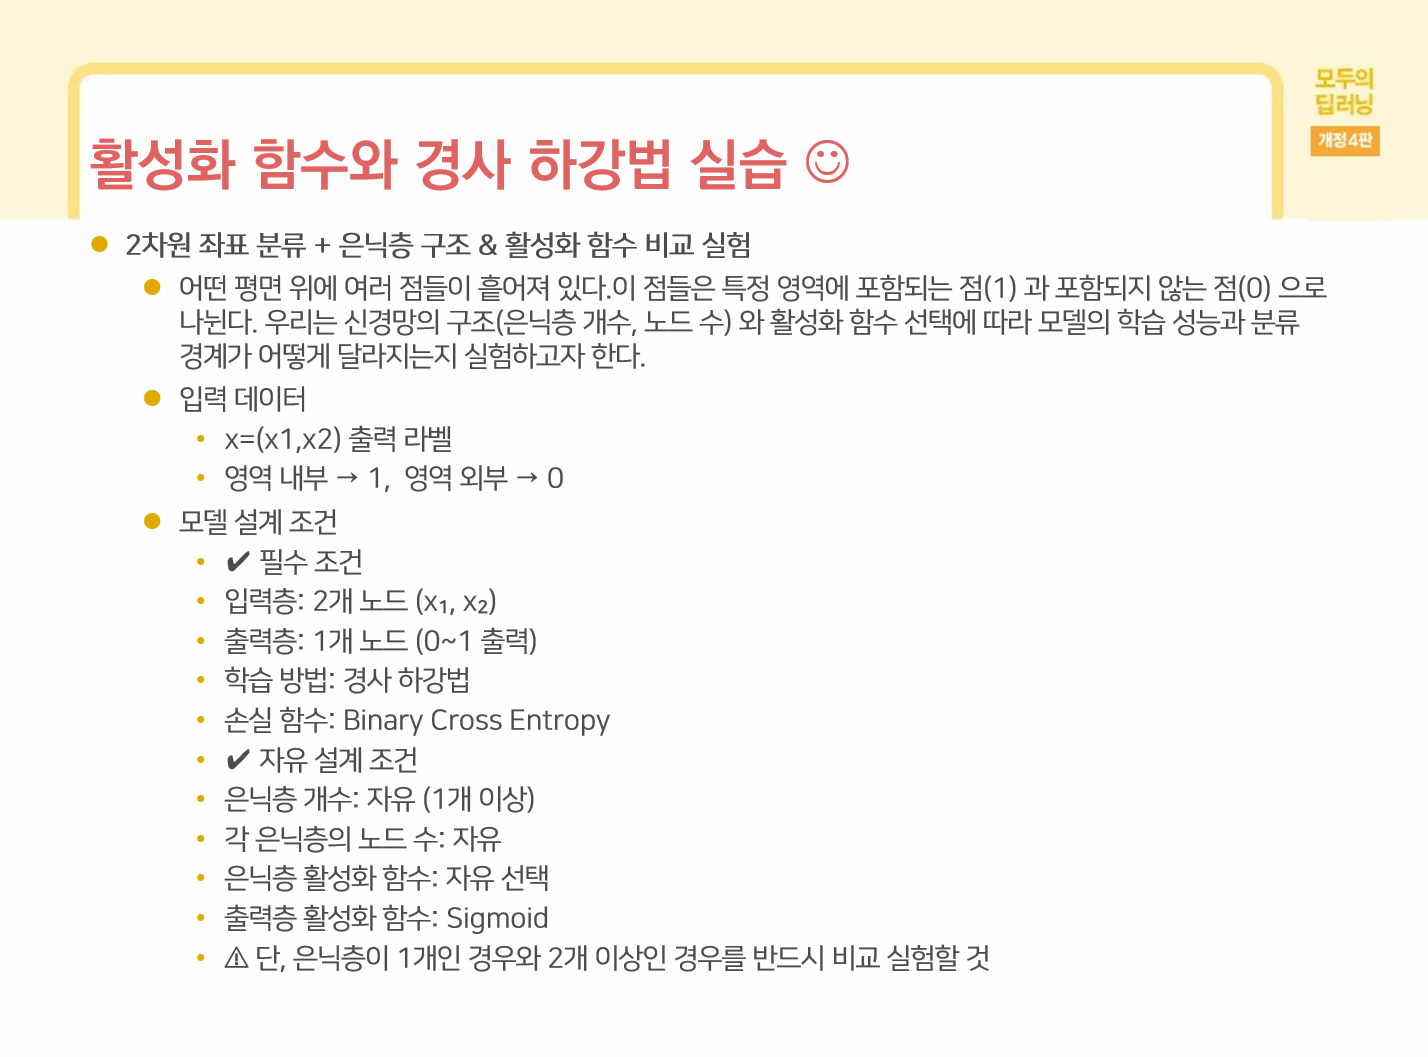

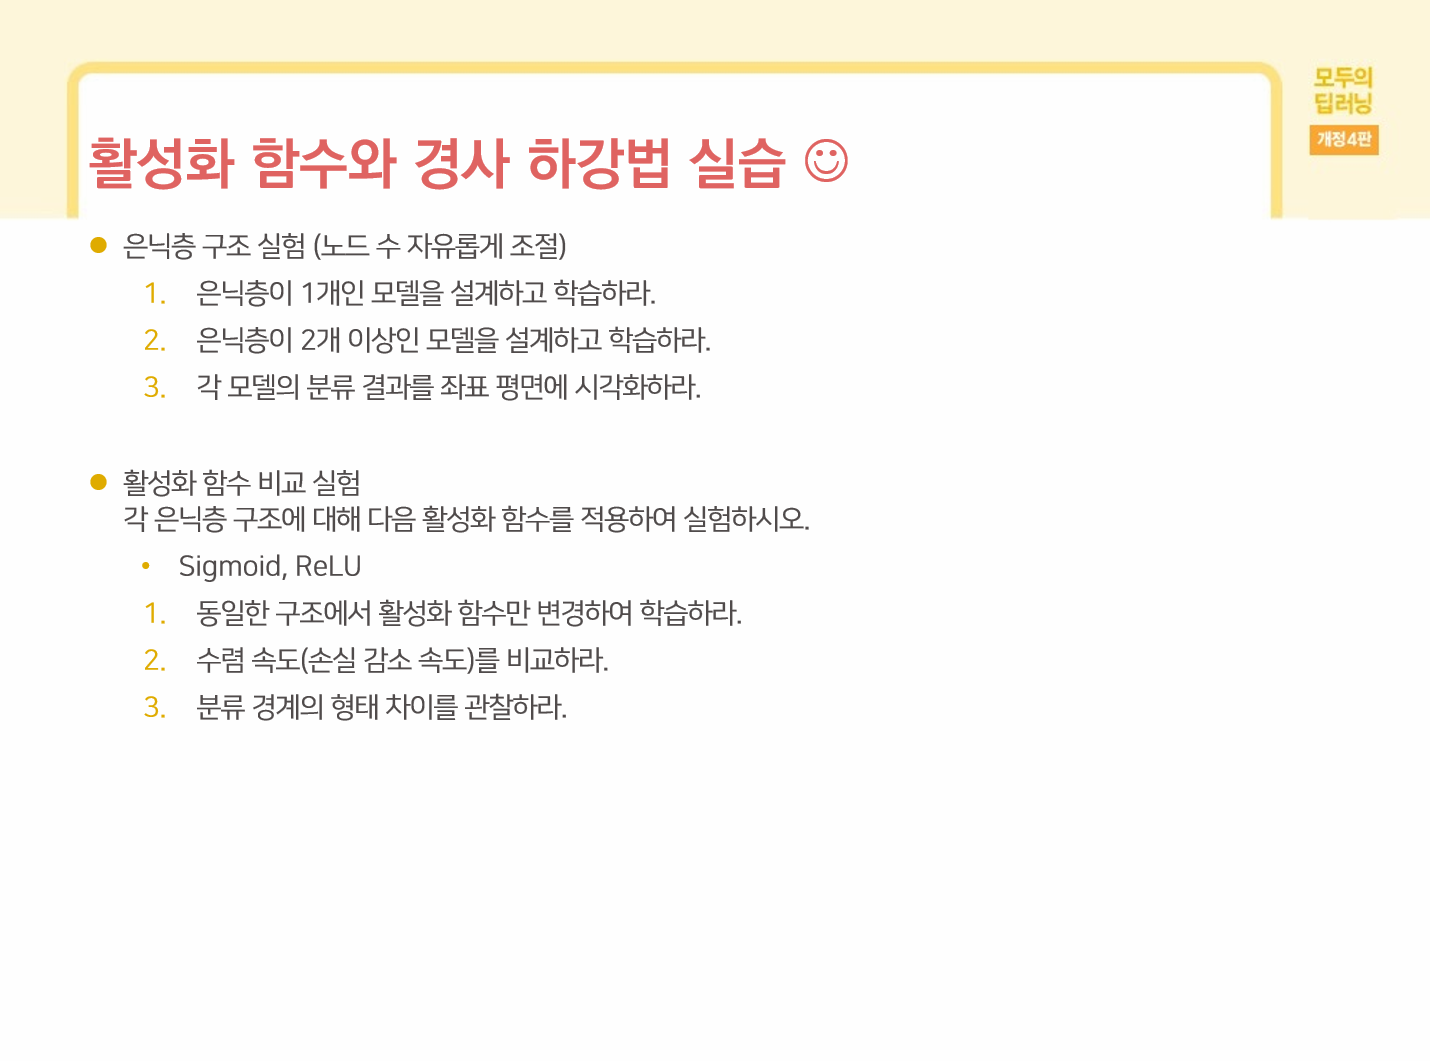

In [2]:
df = pd.read_csv('./ch09_data.csv')

In [3]:
df

,x1,x2,label
0,-0.376380,1.352143,0
1,0.695982,0.295975,1
2,-1.031944,-1.032016,0
3,-1.325749,1.098528,0
4,0.303345,0.624218,1
...,...,...,...
2995,-1.460156,0.126046,0
2996,-0.121311,-0.003096,1
2997,-1.283360,0.553306,0
2998,0.009661,0.795447,1


In [9]:
df.isna().sum()

x1       0
x2       0
label    0
dtype: int64

In [4]:
x = df.drop(columns='label')
y = df['label']

In [5]:
X_train, X_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)

In [10]:
X_train.shape

(2400, 2)

In [ ]:
#은닉층 없이 기본으로 돌려보았다.
model = Sequential()
model.add(Dense(1, input_dim=2, activation='sigmoid'))

# 교차 엔트로피 오차 함수를 이용하기 위하여 'binary_crossentropy'로 설정합니다. 
model.compile(optimizer='sgd' ,loss='binary_crossentropy' , metrics=['accuracy'])

model.fit(X_train, y_train, epochs=1000)

Epoch 1/1000
75/75 ━━━━━━━━━━━━━━━━━━━━ 0s 766us/step - accuracy: 0.4754 - loss: 0.7422 
Epoch 2/1000
75/75 ━━━━━━━━━━━━━━━━━━━━ 0s 916us/step - accuracy: 0.4704 - loss: 0.7153
Epoch 3/1000
75/75 ━━━━━━━━━━━━━━━━━━━━ 0s 711us/step - accuracy: 0.4542 - loss: 0.6957
Epoch 4/1000
75/75 ━━━━━━━━━━━━━━━━━━━━ 0s 753us/step - accuracy: 0.4554 - loss: 0.6814
Epoch 5/1000
75/75 ━━━━━━━━━━━━━━━━━━━━ 0s 774us/step - accuracy: 0.4938 - loss: 0.6709
Epoch 6/1000
75/75 ━━━━━━━━━━━━━━━━━━━━ 0s 942us/step - accuracy: 0.5717 - loss: 0.6635
Epoch 7/1000
75/75 ━━━━━━━━━━━━━━━━━━━━ 0s 702us/step - accuracy: 0.6354 - loss: 0.6580
Epoch 8/1000
75/75 ━━━━━━━━━━━━━━━━━━━━ 0s 710us/step - accuracy: 0.6558 - loss: 0.6541
Epoch 9/1000
75/75 ━━━━━━━━━━━━━━━━━━━━ 0s 798us/step - accuracy: 0.6558 - loss: 0.6512
Epoch 10/1000
75/75 ━━━━━━━━━━━━━━━━━━━━ 0s 866us/step - accuracy: 0.6558 - loss: 0.6491
Epoch 11/1000
75/75 ━━━━━━━━━━━━━━━━━━━━ 0s 794us/step - accuracy: 0.6558 - loss: 0.6475
Epoch 12/1000
75/75 ━━━━━━━━━

In [ ]:
#loss값이 일단 0.64로 굉장히 높게 나왔다.
y_pred_proba = model.predict(X_train)
y_pred = (y_pred_proba > 0.5).astype(int)

train_loss = model.evaluate(X_train, y_train, verbose=0)
test_loss = model.evaluate(X_test, y_test, verbose=0)
print(f"훈련 Loss: {train_loss}")
print(f"테스트 Loss: {test_loss}")

75/75 ━━━━━━━━━━━━━━━━━━━━ 0s 594us/step
훈련 Loss: [0.6428283452987671, 0.6558333039283752]
테스트 Loss: [0.6441255211830139, 0.6600000262260437]


In [14]:
y_pred = (model.predict(X_train) > 0.5).astype(int)

print("혼돈 행렬")
print(confusion_matrix(y_train, y_pred))

75/75 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
혼돈 행렬
[[1574    0]
 [ 826    0]]


In [12]:
#은닉층에 노드수 8로 해서 활성화 함수는 relu로 돌려보았다.
model = Sequential()
model.add(Dense(8, input_dim=2, activation='relu'))
model.add(Dense(1, activation='sigmoid'))

# 교차 엔트로피 오차 함수를 이용하기 위하여 'binary_crossentropy'로 설정합니다. 
model.compile(optimizer='sgd' ,loss='binary_crossentropy', metrics=['accuracy'])

model.fit(X_train, y_train, epochs=500)

Epoch 1/500
75/75 ━━━━━━━━━━━━━━━━━━━━ 0s 913us/step - accuracy: 0.5208 - loss: 0.6742 
Epoch 2/500
75/75 ━━━━━━━━━━━━━━━━━━━━ 0s 689us/step - accuracy: 0.5467 - loss: 0.6385
Epoch 3/500
75/75 ━━━━━━━━━━━━━━━━━━━━ 0s 628us/step - accuracy: 0.5571 - loss: 0.6191
Epoch 4/500
75/75 ━━━━━━━━━━━━━━━━━━━━ 0s 851us/step - accuracy: 0.6033 - loss: 0.6073
Epoch 5/500
75/75 ━━━━━━━━━━━━━━━━━━━━ 0s 819us/step - accuracy: 0.6408 - loss: 0.5990
Epoch 6/500
75/75 ━━━━━━━━━━━━━━━━━━━━ 0s 823us/step - accuracy: 0.6558 - loss: 0.5925
Epoch 7/500
75/75 ━━━━━━━━━━━━━━━━━━━━ 0s 809us/step - accuracy: 0.6558 - loss: 0.5869
Epoch 8/500
75/75 ━━━━━━━━━━━━━━━━━━━━ 0s 780us/step - accuracy: 0.6558 - loss: 0.5819
Epoch 9/500
75/75 ━━━━━━━━━━━━━━━━━━━━ 0s 589us/step - accuracy: 0.6558 - loss: 0.5772
Epoch 10/500
75/75 ━━━━━━━━━━━━━━━━━━━━ 0s 808us/step - accuracy: 0.6558 - loss: 0.5726
Epoch 11/500
75/75 ━━━━━━━━━━━━━━━━━━━━ 0s 777us/step - accuracy: 0.6558 - loss: 0.5681
Epoch 12/500
75/75 ━━━━━━━━━━━━━━━━━━━━ 

In [13]:
#확실히 정확도와 로스가 많이 떨어진것을 확인할 수 있었다.
y_pred_proba = model.predict(X_train)
y_pred = (y_pred_proba > 0.5).astype(int)

train_loss = model.evaluate(X_train, y_train, verbose=0)
test_loss = model.evaluate(X_test, y_test, verbose=0)
print(f"훈련 Loss: {train_loss}")
print(f"테스트 Loss: {test_loss}")

75/75 ━━━━━━━━━━━━━━━━━━━━ 0s 670us/step
훈련 Loss: [0.08855219185352325, 0.9800000190734863]
테스트 Loss: [0.09252911061048508, 0.9833333492279053]


In [ ]:
#활성화함수를 시그모이드로 바꾸어서 돌려주었다.
model = Sequential()
model.add(Dense(8, input_dim=2, activation='sigmoid'))
model.add(Dense(1, activation='sigmoid'))

# 교차 엔트로피 오차 함수를 이용하기 위하여 'binary_crossentropy'로 설정합니다. 
model.compile(optimizer='sgd' ,loss='binary_crossentropy', metrics=['accuracy'])

model.fit(X_train, y_train, epochs=500)

Epoch 1/500
75/75 ━━━━━━━━━━━━━━━━━━━━ 0s 846us/step - accuracy: 0.5917 - loss: 0.6735
Epoch 2/500
75/75 ━━━━━━━━━━━━━━━━━━━━ 0s 769us/step - accuracy: 0.6558 - loss: 0.6549
Epoch 3/500
75/75 ━━━━━━━━━━━━━━━━━━━━ 0s 782us/step - accuracy: 0.6558 - loss: 0.6491
Epoch 4/500
75/75 ━━━━━━━━━━━━━━━━━━━━ 0s 845us/step - accuracy: 0.6558 - loss: 0.6472
Epoch 5/500
75/75 ━━━━━━━━━━━━━━━━━━━━ 0s 649us/step - accuracy: 0.6558 - loss: 0.6463
Epoch 6/500
75/75 ━━━━━━━━━━━━━━━━━━━━ 0s 736us/step - accuracy: 0.6558 - loss: 0.6460
Epoch 7/500
75/75 ━━━━━━━━━━━━━━━━━━━━ 0s 798us/step - accuracy: 0.6558 - loss: 0.6458
Epoch 8/500
75/75 ━━━━━━━━━━━━━━━━━━━━ 0s 872us/step - accuracy: 0.6558 - loss: 0.6457
Epoch 9/500
75/75 ━━━━━━━━━━━━━━━━━━━━ 0s 772us/step - accuracy: 0.6558 - loss: 0.6455
Epoch 10/500
75/75 ━━━━━━━━━━━━━━━━━━━━ 0s 879us/step - accuracy: 0.6558 - loss: 0.6455
Epoch 11/500
75/75 ━━━━━━━━━━━━━━━━━━━━ 0s 833us/step - accuracy: 0.6558 - loss: 0.6454
Epoch 12/500
75/75 ━━━━━━━━━━━━━━━━━━━━ 0

In [ ]:
#relu로 돌렸을때와 비교하면 로스는 조금 줄었지만 유의미하지 않다는 것을 확인할 수있었고
#은닉층을 만든다는건 미분값을 곱해나가는 것인데 sigmoid의 경우에는 미분했을때 기울기가 거의 상실되어
#거의 사용할 수 없다는 것을 다시 확인하였다.
y_pred_proba = model.predict(X_train)
y_pred = (y_pred_proba > 0.5).astype(int)

train_loss = model.evaluate(X_train, y_train, verbose=0)
test_loss = model.evaluate(X_test, y_test, verbose=0)
print(f"훈련 Loss: {train_loss}")
print(f"테스트 Loss: {test_loss}")

75/75 ━━━━━━━━━━━━━━━━━━━━ 0s 610us/step
훈련 Loss: [0.5695833563804626, 0.6558333039283752]
테스트 Loss: [0.5775852203369141, 0.6600000262260437]


In [ ]:
#은닉층을 2개로 늘려보았다.
model = Sequential()
model.add(Dense(8, input_dim=2, activation='relu'))
model.add(Dense(4, activation='relu'))
model.add(Dense(1, activation='sigmoid'))

# 교차 엔트로피 오차 함수를 이용하기 위하여 'binary_crossentropy'로 설정합니다. 
model.compile(optimizer='sgd' ,loss='binary_crossentropy', metrics=['accuracy'])

model.fit(X_train, y_train, epochs=500)

Epoch 1/500
75/75 ━━━━━━━━━━━━━━━━━━━━ 0s 840us/step - accuracy: 0.5971 - loss: 0.6793
Epoch 2/500
75/75 ━━━━━━━━━━━━━━━━━━━━ 0s 821us/step - accuracy: 0.6558 - loss: 0.6605
Epoch 3/500
75/75 ━━━━━━━━━━━━━━━━━━━━ 0s 757us/step - accuracy: 0.6558 - loss: 0.6475
Epoch 4/500
75/75 ━━━━━━━━━━━━━━━━━━━━ 0s 807us/step - accuracy: 0.6558 - loss: 0.6383
Epoch 5/500
75/75 ━━━━━━━━━━━━━━━━━━━━ 0s 869us/step - accuracy: 0.6558 - loss: 0.6312
Epoch 6/500
75/75 ━━━━━━━━━━━━━━━━━━━━ 0s 771us/step - accuracy: 0.6558 - loss: 0.6260
Epoch 7/500
75/75 ━━━━━━━━━━━━━━━━━━━━ 0s 787us/step - accuracy: 0.6558 - loss: 0.6218
Epoch 8/500
75/75 ━━━━━━━━━━━━━━━━━━━━ 0s 836us/step - accuracy: 0.6558 - loss: 0.6180
Epoch 9/500
75/75 ━━━━━━━━━━━━━━━━━━━━ 0s 772us/step - accuracy: 0.6558 - loss: 0.6143
Epoch 10/500
75/75 ━━━━━━━━━━━━━━━━━━━━ 0s 791us/step - accuracy: 0.6558 - loss: 0.6107
Epoch 11/500
75/75 ━━━━━━━━━━━━━━━━━━━━ 0s 600us/step - accuracy: 0.6558 - loss: 0.6068
Epoch 12/500
75/75 ━━━━━━━━━━━━━━━━━━━━ 0

In [ ]:
#확실히 정확도가 높아졌으며 loss가 훨씬 감소하였음을 확인하였다.
y_pred_proba = model.predict(X_train)
y_pred = (y_pred_proba > 0.5).astype(int)

train_loss = model.evaluate(X_train, y_train, verbose=0)
test_loss = model.evaluate(X_test, y_test, verbose=0)
print(f"훈련 Loss: {train_loss}")
print(f"테스트 Loss: {test_loss}")

75/75 ━━━━━━━━━━━━━━━━━━━━ 0s 656us/step
훈련 Loss: [0.02588704042136669, 0.9933333396911621]
테스트 Loss: [0.025828368961811066, 0.996666669845581]
[[1]
 [0]
 [0]
 ...
 [1]
 [0]
 [0]]


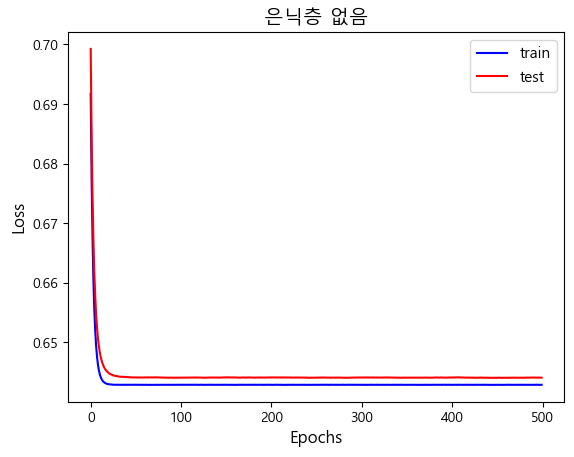

In [ ]:
#은닉층이 없을때 에포크에 따른 loss는 선형이기 때문에 처음에 확 떨어지는 것처럼 보이지만 0.6정도까지만 떨어지는 것을 확인할 수있다.
model = Sequential()
model.add(Dense(1, input_dim=2, activation='sigmoid'))

# 교차 엔트로피 오차 함수를 이용하기 위하여 'binary_crossentropy'로 설정합니다. 
model.compile(optimizer='sgd' ,loss='binary_crossentropy' , metrics=['accuracy'])

history = model.fit(X_train, y_train, epochs=500, validation_data=(X_test, y_test), verbose=0)
plt.plot(history.history['loss'], label='train', color='blue')
plt.plot(history.history['val_loss'], label='test', color='red')

plt.title('은닉층 없음', fontsize=14)
plt.xlabel('Epochs', fontsize=12)
plt.ylabel('Loss', fontsize=12)
plt.legend(fontsize=11)

plt.show()

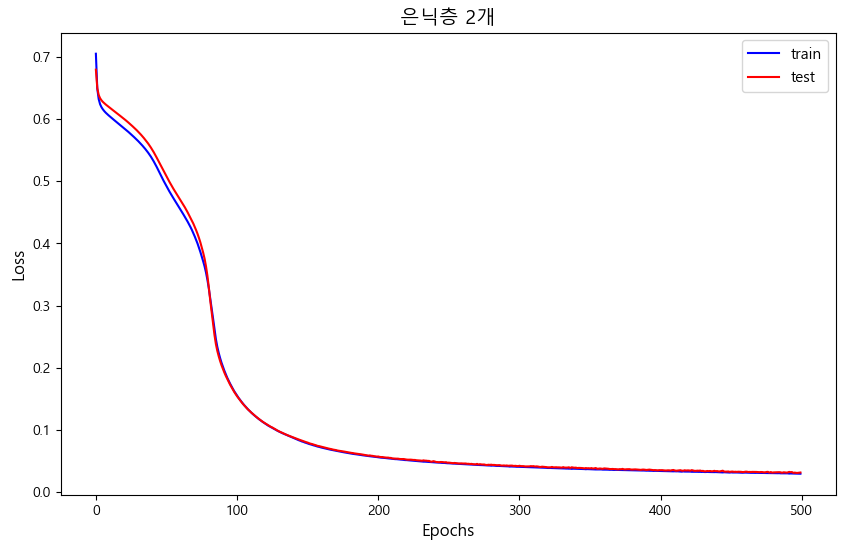

In [ ]:
#은닉층이 2개일때 값들이 꼬불꼬불 나오지만 테스트값과 오차가 거의 없으며 안정적으로 쭉 떨어지는것을 확인할수있다.
model = Sequential()
model.add(Dense(8, input_dim=2, activation='relu'))
model.add(Dense(4, activation='relu'))
model.add(Dense(1, activation='sigmoid'))

# 교차 엔트로피 오차 함수를 이용하기 위하여 'binary_crossentropy'로 설정합니다. 
model.compile(optimizer='sgd' ,loss='binary_crossentropy', metrics=['accuracy'])

history = model.fit(X_train, y_train, epochs=500, validation_data=(X_test, y_test), verbose=0)
plt.figure(figsize=(10, 6))

plt.plot(history.history['loss'], label='train', color='blue')
plt.plot(history.history['val_loss'], label='test', color='red')

plt.title('은닉층 2개', fontsize=14)
plt.xlabel('Epochs', fontsize=12)
plt.ylabel('Loss', fontsize=12)
plt.legend(fontsize=11)

plt.show()

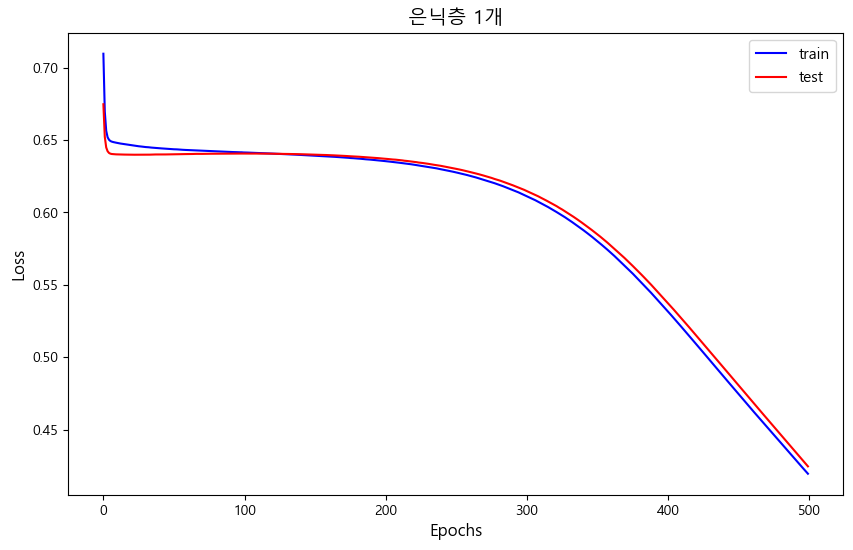

In [ ]:
#은닉층이 1개일때는 2개일때보다 꼬불꼬불 거리는게 덜하지만 로스값이 덜 떨어진다.
model = Sequential()
model.add(Dense(8, input_dim=2, activation='sigmoid'))
model.add(Dense(1, activation='sigmoid'))

# 교차 엔트로피 오차 함수를 이용하기 위하여 'binary_crossentropy'로 설정합니다. 
model.compile(optimizer='sgd' ,loss='binary_crossentropy', metrics=['accuracy'])

history = model.fit(X_train, y_train, epochs=500, validation_data=(X_test, y_test), verbose=0)
plt.figure(figsize=(10, 6))


plt.plot(history.history['loss'], label='train', color='blue')
plt.plot(history.history['val_loss'], label='test', color='red')

plt.title('은닉층 1개', fontsize=14)
plt.xlabel('Epochs', fontsize=12)
plt.ylabel('Loss', fontsize=12)
plt.legend(fontsize=11)

plt.show()

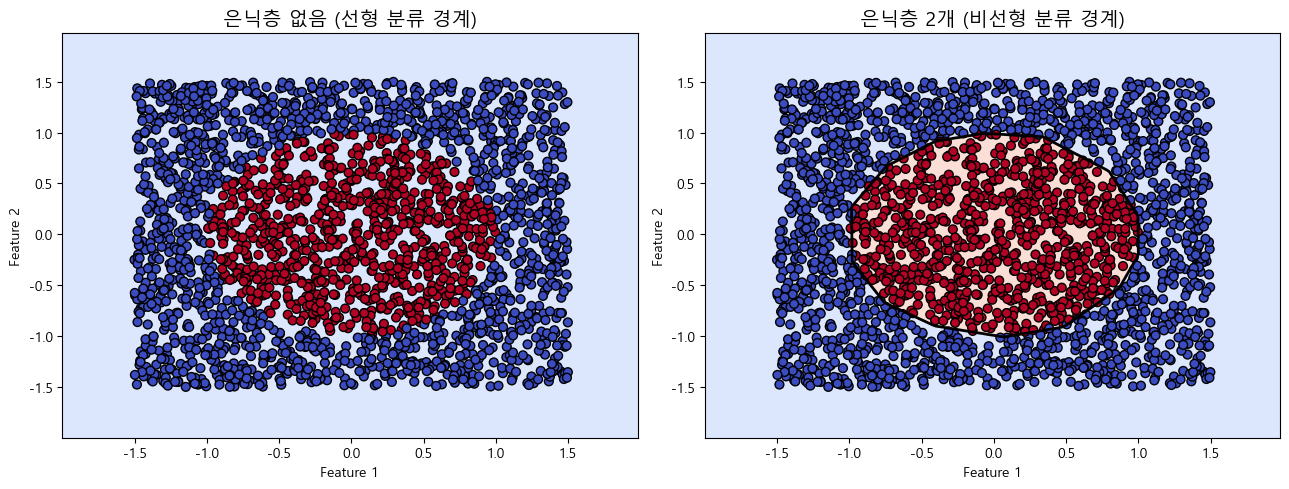

In [ ]:
# 1. 시각화용 분류 경계 그리기 함수 정의
def plot_decision_boundary(model, X, y, title):
    # 데이터의 최소/최대 범위를 기반으로 2차원 격자(Grid) 생성
    x_min, x_max = X[:, 0].min() - 0.5, X[:, 0].max() + 0.5
    y_min, y_max = X[:, 1].min() - 0.5, X[:, 1].max() + 0.5
    xx, yy = np.meshgrid(np.arange(x_min, x_max, 0.02),
                         np.arange(y_min, y_max, 0.02))
    
    # 격자의 모든 좌표점에 대해 모델의 예측값(확률) 계산
    grid_points = np.c_[xx.ravel(), yy.ravel()]
    Z = model.predict(grid_points, verbose=0)
    Z = Z.reshape(xx.shape)
    
    # 배경에 예측 경계 영역 채우기 (0.5 기준으로 색 분할)
    plt.contourf(xx, yy, Z, levels=[0, 0.5, 1.0], alpha=0.3, cmap=plt.cm.coolwarm)
    # 경계 선만 따로 진하게 표시
    plt.contour(xx, yy, Z, levels=[0.5], colors='k', linewidths=2)
    
    # 실제 데이터 포인트 산점도로 표시
    plt.scatter(X[:, 0], X[:, 1], c=y.flatten(), cmap=plt.cm.coolwarm, edgecolors='k', s=40)
    plt.title(title, fontsize=14)
    plt.xlabel('Feature 1')
    plt.ylabel('Feature 2')

# NumPy 배열 형태로 입력 데이터 변환 (DataFrame인 경우 .values 적용)
X_data = X_train.values if hasattr(X_train, 'values') else np.array(X_train)
y_data = y_train.values if hasattr(y_train, 'values') else np.array(y_train)

# 2. 은닉층 없는 모델 (선형 경계)
model_0 = Sequential([
    Dense(1, input_dim=2, activation='sigmoid')
])
model_0.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
model_0.fit(X_data, y_data, epochs=500, verbose=0)

# 3. 은닉층 2개인 모델 (비선형 경계)
model_2 = Sequential([
    Dense(8, input_dim=2, activation='relu'),
    Dense(4, activation='relu'),
    Dense(1, activation='sigmoid')
])
model_2.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
model_2.fit(X_data, y_data, epochs=500, verbose=0)

# 4. 두 모델의 분류 경계 한 화면에 출력하기
plt.figure(figsize=(13, 5))

plt.subplot(1, 2, 1)
plot_decision_boundary(model_0, X_data, y_data, '은닉층 없음 (선형 분류 경계)')

plt.subplot(1, 2, 2)
plot_decision_boundary(model_2, X_data, y_data, '은닉층 2개 (비선형 분류 경계)')

plt.tight_layout()
plt.show()
#가운데 부분에 배경이 생겼다는게 중요하다
